# Assignment 3: MNIST GAN

A PyTorch GAN using the architecture specified in Assignment 3, organized like the Module 6 practical. This uses MNIST and binary cross-entropy rather than the CelebA Wasserstein objective.

The saved run contains ten epochs: epochs 1-5 were followed by a resumed run for epochs 6-10, with one demonstration batch update before epoch 1. Saved outputs are retained for inspection; ten epochs is an experiment setting, not an assignment requirement.

## 1. Imports and Configuration

The default restores the saved experiment without repeating training. Set `resume = False` to train a new ten-epoch run in a separate directory.

In [1]:
from pathlib import Path
import time
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torchvision.utils import make_grid, save_image
from tqdm import tqdm

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
z_dim = 100
lr = 0.0002
epochs = 10
resume = True
run_dir = Path("outputs/gan_20261027_224535")
if not resume:
    run_dir = Path("outputs") / time.strftime("gan_%Y%m%d_%H%M%S")
sample_dir = run_dir / "samples"
checkpoint_dir = run_dir / "checkpoints"
sample_dir.mkdir(parents=True, exist_ok=True)
checkpoint_dir.mkdir(parents=True, exist_ok=True)
print("Device:", device)
print("Run directory:", run_dir)

Device: cpu
Run directory: outputs\gan_20261027_224535


## 2. MNIST Data

Normalize 28-by-28 grayscale images to [-1, 1] to match the generator output. Digit labels are not used for unconditional GAN training.

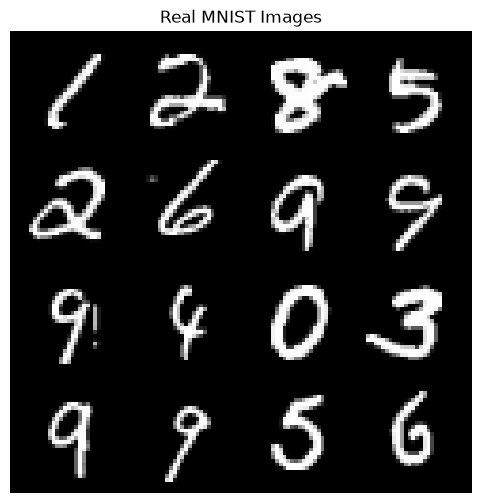

Training samples: 60000
Batch shape: (64, 1, 28, 28)


In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])
dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
real, labels = next(iter(dataloader))
print("Training samples:", len(dataset))
print("Batch shape:", tuple(real.shape))
grid = make_grid((real[:16] + 1) / 2, nrow=4)
plt.figure(figsize=(6, 6))
plt.imshow(grid.permute(1, 2, 0))
plt.title("Real MNIST Images")
plt.axis("off")
plt.show()
plt.close()

## 3. Discriminator

Two convolutional blocks reduce the spatial dimensions from 28 to 14 to 7. The final sigmoid produces a real/fake probability for binary cross-entropy.

In [3]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 64, 4, 2, 1)
        self.act1 = nn.LeakyReLU(0.2)
        self.conv2 = nn.Conv2d(64, 128, 4, 2, 1)
        self.batchnorm2 = nn.BatchNorm2d(128)
        self.act2 = nn.LeakyReLU(0.2)
        self.flatten = nn.Flatten()
        self.fc = nn.Linear(128 * 7 * 7, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.conv1(x)
        x = self.act1(x)
        x = self.conv2(x)
        x = self.batchnorm2(x)
        x = self.act2(x)
        x = self.flatten(x)
        x = self.fc(x)
        return self.sigmoid(x)

## 4. Generator

A fully connected layer maps 100-dimensional noise to 128-by-7-by-7 features. Two transposed convolutions produce a 1-by-28-by-28 image with Tanh output.

In [4]:
class Generator(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()
        self.z_dim = z_dim
        self.fc = nn.Linear(z_dim, 128 * 7 * 7)
        self.deconv1 = nn.ConvTranspose2d(128, 64, 4, 2, 1)
        self.bn1 = nn.BatchNorm2d(64)
        self.act1 = nn.ReLU()
        self.deconv2 = nn.ConvTranspose2d(64, 1, 4, 2, 1)
        self.tanh = nn.Tanh()

    def forward(self, x):
        x = self.fc(x)
        x = x.view(x.size(0), 128, 7, 7)
        x = self.deconv1(x)
        x = self.bn1(x)
        x = self.act1(x)
        x = self.deconv2(x)
        return self.tanh(x)

## 5. Models and Optimizers

Restore the final checkpoint by default, including both optimizers and the fixed noise. Restarted training is not guaranteed to reproduce an uninterrupted run because the original checkpoints did not record all random-number states.

In [5]:
gen = Generator(z_dim).to(device)
disc = Discriminator().to(device)
criterion = nn.BCELoss()
opt_gen = optim.Adam(gen.parameters(), lr=lr, betas=(0.5, 0.999))
opt_disc = optim.Adam(disc.parameters(), lr=lr, betas=(0.5, 0.999))
fixed_noise = torch.randn(16, z_dim, device=device)
datalogs = []
start_epoch = 0

if resume:
    resume_path = checkpoint_dir / "gan_epoch_010.pth"
    checkpoint = torch.load(resume_path, map_location=device, weights_only=True)
    gen.load_state_dict(checkpoint["generator_state_dict"])
    disc.load_state_dict(checkpoint["discriminator_state_dict"])
    opt_gen.load_state_dict(checkpoint["optimizer_G_state_dict"])
    opt_disc.load_state_dict(checkpoint["optimizer_D_state_dict"])
    fixed_noise = checkpoint["fixed_noise"].to(device)
    datalogs = checkpoint["datalogs"]
    start_epoch = checkpoint["epoch"]
    print("Loaded checkpoint:", resume_path)

print("Completed epochs:", start_epoch)
print("Target epochs:", epochs)
print("Remaining epochs:", max(0, epochs - start_epoch))


Loaded checkpoint: outputs\gan_20261027_224535\checkpoints\gan_epoch_010.pth
Completed epochs: 10
Target epochs: 10
Remaining epochs: 0


## 6. Training

Alternate discriminator and generator updates, using tqdm as in the classroom practical. Each completed epoch saves a separate checkpoint and sample grid; the default completed run skips further updates.

In [6]:
for epoch in range(start_epoch, epochs):
    epoch_number = epoch + 1
    start_time = time.perf_counter()

    gen.train()
    disc.train()
    disc.requires_grad_(True)

    running_loss_D = 0.0
    running_loss_G = 0.0
    total_images = 0

    train_loader_with_progress = tqdm(
        dataloader,
        ncols=100,
        desc=f"Epoch {epoch_number}",
    )

    for batch_number, (real, _) in enumerate(
        train_loader_with_progress,
        start=1,
    ):
        real = real.to(device)
        current_batch_size = real.size(0)

        real_targets = torch.ones(
            current_batch_size, 1, device=device
        )
        fake_targets = torch.zeros(
            current_batch_size, 1, device=device
        )

        # Train Discriminator
        opt_disc.zero_grad(set_to_none=True)

        predictions_real = disc(real)
        loss_real = criterion(predictions_real, real_targets)

        noise = torch.randn(
            current_batch_size, z_dim, device=device
        )

        with torch.no_grad():
            fake = gen(noise)

        predictions_fake = disc(fake)
        loss_fake = criterion(predictions_fake, fake_targets)

        loss_D = (loss_real + loss_fake) / 2

        if not torch.isfinite(loss_D).item():
            raise RuntimeError("Discriminator loss is not finite.")

        loss_D.backward()
        opt_disc.step()

        # Train Generator
        opt_disc.zero_grad(set_to_none=True)
        disc.requires_grad_(False)

        try:
            opt_gen.zero_grad(set_to_none=True)

            noise = torch.randn(
                current_batch_size, z_dim, device=device
            )

            fake = gen(noise)
            predictions_fake = disc(fake)

            loss_G = criterion(
                predictions_fake,
                torch.ones_like(predictions_fake),
            )

            if not torch.isfinite(loss_G).item():
                raise RuntimeError("Generator loss is not finite.")

            loss_G.backward()
            opt_gen.step()

        finally:
            disc.requires_grad_(True)

        # Accumulate losses
        running_loss_D += loss_D.item() * current_batch_size
        running_loss_G += loss_G.item() * current_batch_size
        total_images += current_batch_size

        if (
            batch_number == 1
            or batch_number % 100 == 0
            or batch_number == len(dataloader)
        ):
            train_loader_with_progress.set_postfix({
                "D loss": f"{loss_D.item():.4f}",
                "G loss": f"{loss_G.item():.4f}",
            })

    # Record epoch results
    average_loss_D = running_loss_D / total_images
    average_loss_G = running_loss_G / total_images
    elapsed_seconds = time.perf_counter() - start_time

    completed_epochs = epoch_number

    datalogs.append({
        "epoch": epoch_number,
        "D loss": average_loss_D,
        "G loss": average_loss_G,
        "seconds": elapsed_seconds,
    })

    # Generate samples from fixed noise
    gen.eval()

    with torch.no_grad():
        samples = gen(fixed_noise).cpu()

    samples = ((samples + 1) / 2).clamp(0, 1)

    sample_path = sample_dir / f"epoch_{epoch_number:03d}.png"
    save_image(samples, sample_path, nrow=4)

    grid = make_grid(samples, nrow=4)

    plt.figure(figsize=(6, 6))
    plt.imshow(grid.permute(1, 2, 0).numpy())
    plt.title(f"Generated Images - Epoch {epoch_number}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()
    plt.close()

    # Save training checkpoint
    checkpoint_path = (
        checkpoint_dir / f"gan_epoch_{epoch_number:03d}.pth"
    )

    torch.save({
        "epoch": completed_epochs,
        "generator_state_dict": gen.state_dict(),
        "discriminator_state_dict": disc.state_dict(),
        "optimizer_G_state_dict": opt_gen.state_dict(),
        "optimizer_D_state_dict": opt_disc.state_dict(),
        "fixed_noise": fixed_noise.detach().cpu(),
        "datalogs": datalogs,
    }, checkpoint_path)

    print(
        f"Epoch {epoch_number} complete | "
        f"Average D loss: {average_loss_D:.4f} | "
        f"Average G loss: {average_loss_G:.4f} | "
        f"Training time: {elapsed_seconds:.1f}s"
    )
    print("Samples saved:", sample_path)
    print("Checkpoint saved:", checkpoint_path)
start_epoch = max(start_epoch, epochs)
print("Completed epochs:", start_epoch)

Completed epochs: 10


## 7. Results for Every Epoch

Display all saved epoch grids in order using the same fixed noise. This cell reconstructs the full visual history without retraining.

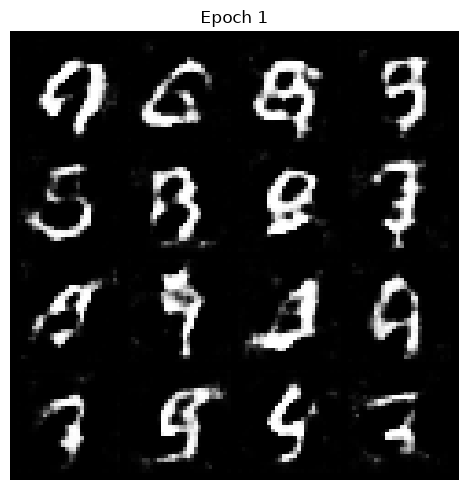

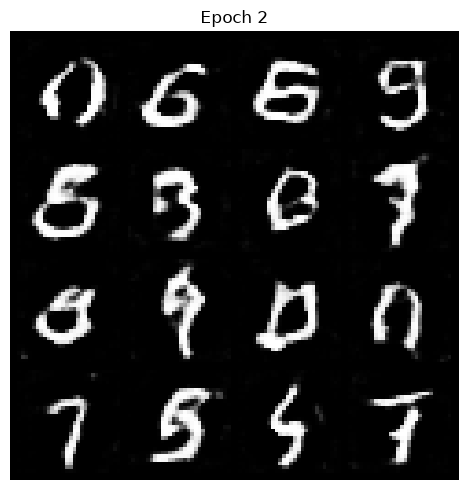

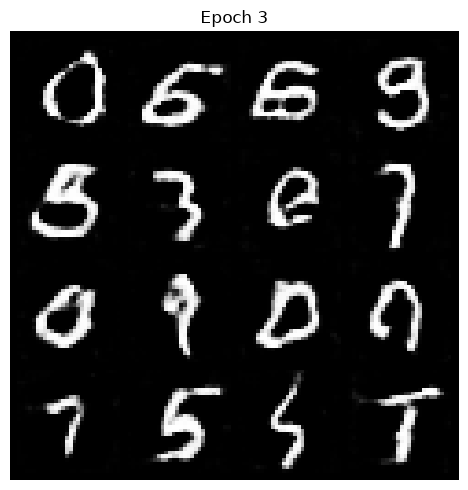

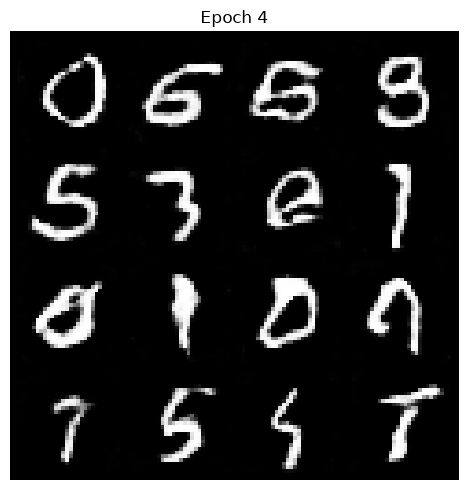

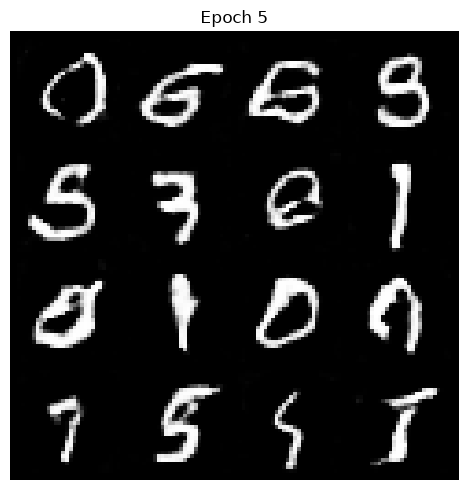

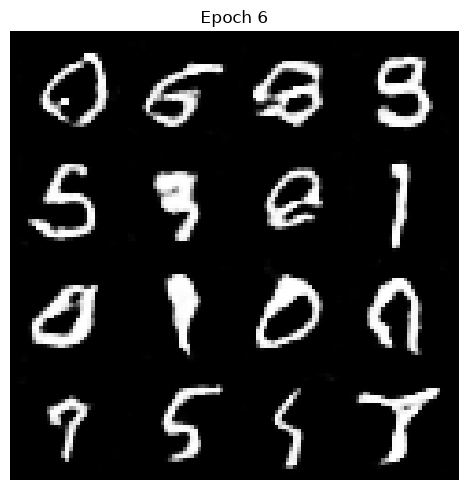

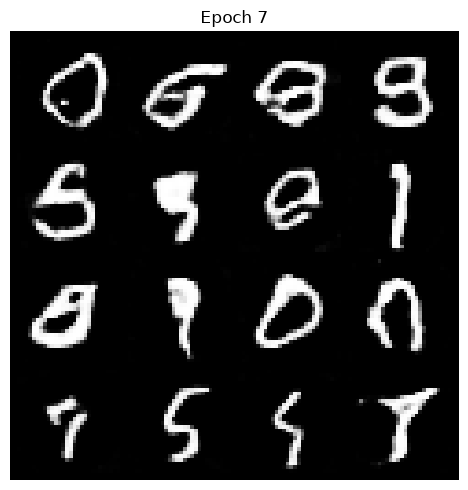

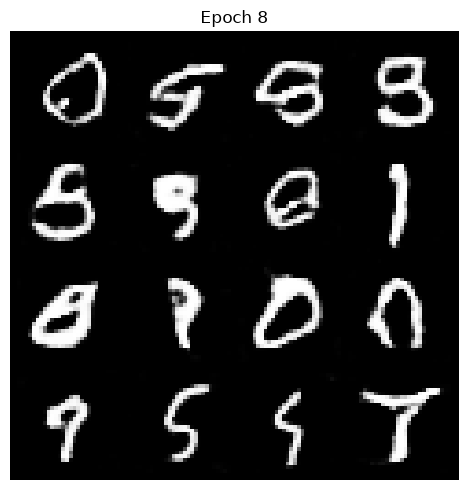

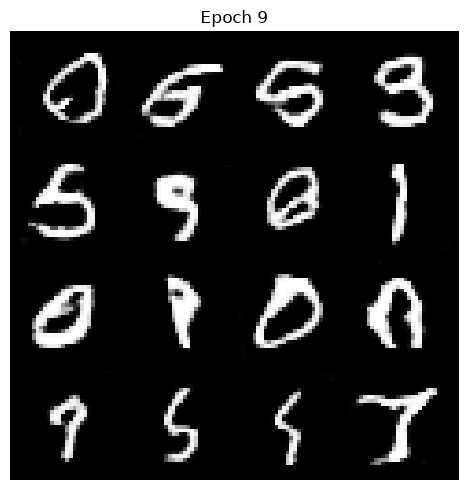

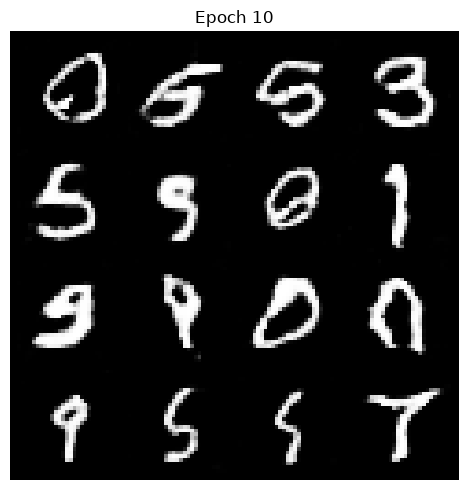

In [7]:
for epoch in range(1, epochs + 1):
    image_path = sample_dir / f"epoch_{epoch:03d}.png"
    if not image_path.exists():
        print(f"Epoch {epoch}: no saved sample image yet.")
        continue
    plt.figure(figsize=(5, 5))
    plt.imshow(plt.imread(image_path))
    plt.title(f"Epoch {epoch}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()
    plt.close()

## 8. Training Loss

Losses are averaged over images within each epoch. GAN losses alone do not establish convergence or image quality.

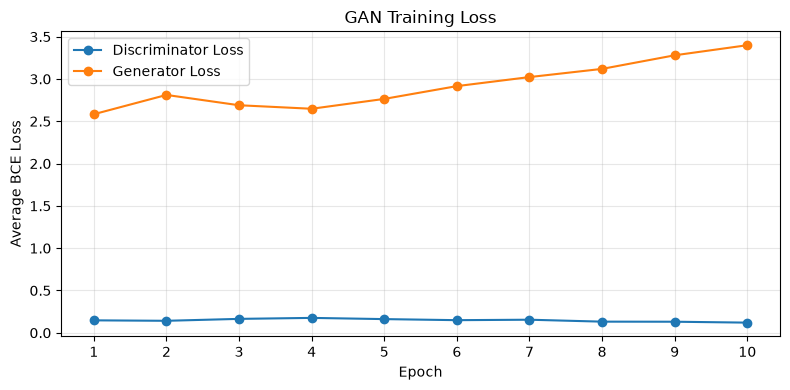

Recorded epochs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


In [8]:
plt.figure(figsize=(8, 4))
plt.plot([r["epoch"] for r in datalogs], [r["D loss"] for r in datalogs], marker="o", label="Discriminator Loss")
plt.plot([r["epoch"] for r in datalogs], [r["G loss"] for r in datalogs], marker="o", label="Generator Loss")
plt.xlabel("Epoch")
plt.ylabel("Average BCE Loss")
plt.title("GAN Training Loss")
plt.xticks([r["epoch"] for r in datalogs])
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(run_dir / f"loss_curve_epoch_{start_epoch:03d}.png", dpi=150)
plt.show()
plt.close()
print("Recorded epochs:", [r["epoch"] for r in datalogs])

## 9. Samples from Fresh Noise

A separate seeded random-number generator provides 64 additional inputs. Visual variety in a small grid does not establish complete digit coverage or rule out mode collapse.

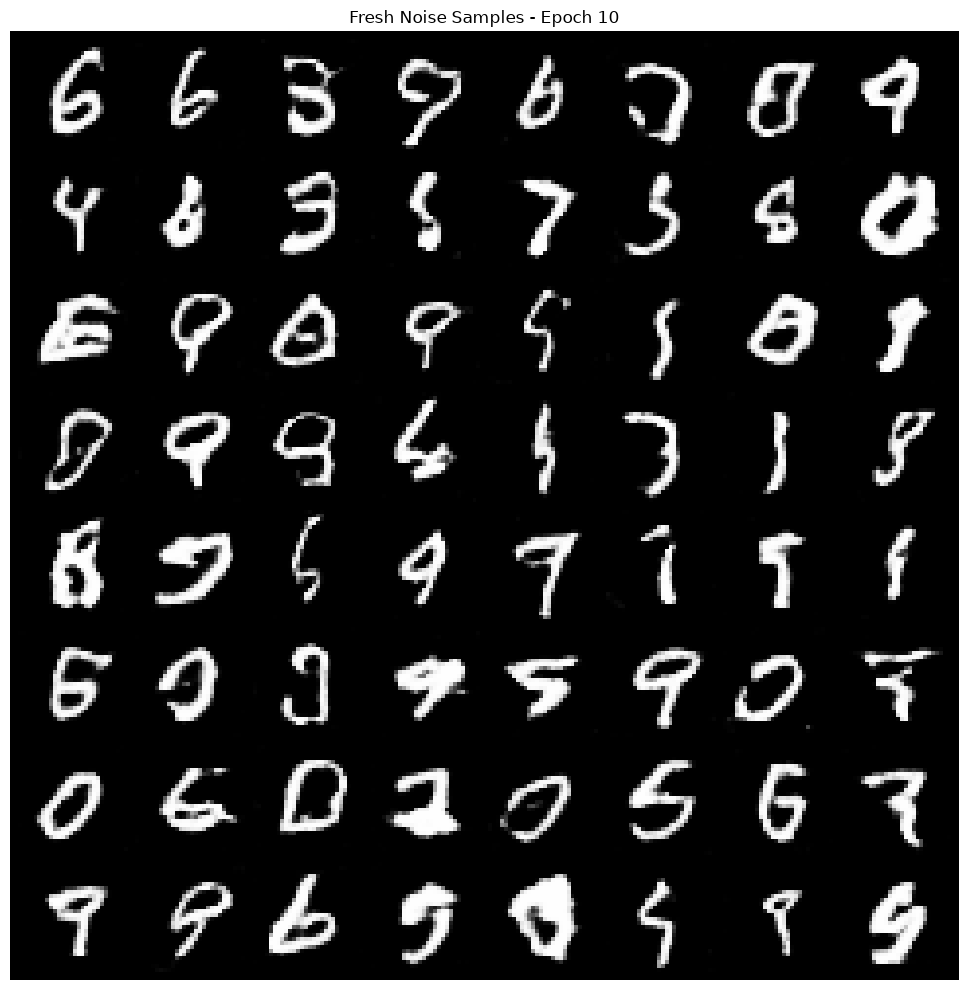

Completed epochs: 10
Samples saved: outputs\gan_20261027_224535\samples\fresh_samples_epoch_010.png


In [9]:
gen.eval()

evaluation_rng = torch.Generator(device="cpu")
evaluation_rng.manual_seed(2026)

evaluation_noise = torch.randn(
    64,
    z_dim,
    generator=evaluation_rng,
).to(device)

with torch.no_grad():
    evaluation_samples = gen(evaluation_noise).cpu()

evaluation_samples = (
    (evaluation_samples + 1) / 2
).clamp(0, 1)

evaluation_path = (
    sample_dir / f"fresh_samples_epoch_{start_epoch:03d}.png"
)

save_image(
    evaluation_samples,
    evaluation_path,
    nrow=8,
)

grid = make_grid(evaluation_samples, nrow=8)

plt.figure(figsize=(10, 10))
plt.imshow(grid.permute(1, 2, 0).numpy())
plt.title(f"Fresh Noise Samples - Epoch {start_epoch}")
plt.axis("off")
plt.tight_layout()
plt.show()
plt.close()

print("Completed epochs:", start_epoch)
print("Samples saved:", evaluation_path)

## 10. Export and Reload Check

Export generator weights for inference and verify that a newly loaded model reproduces the same output. FastAPI and Docker integration are separate deployment steps.

In [10]:
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)
export_path = model_dir / f"mnist_generator_classroom_epoch_{start_epoch:03d}.pth"
weights = {name: value.detach().cpu().clone() for name, value in gen.state_dict().items()}
torch.save(weights, export_path)

restored_gen = Generator(z_dim).to(device)
restored_gen.load_state_dict(torch.load(export_path, map_location=device, weights_only=True))
gen.eval()
restored_gen.eval()
with torch.no_grad():
    expected = gen(fixed_noise)
    actual = restored_gen(fixed_noise)
torch.testing.assert_close(actual, expected)
assert actual.shape == (16, 1, 28, 28)
print("Generator weights saved:", export_path)
print("Reload verification passed.")


Generator weights saved: models\mnist_generator_classroom_epoch_010.pth
Reload verification passed.


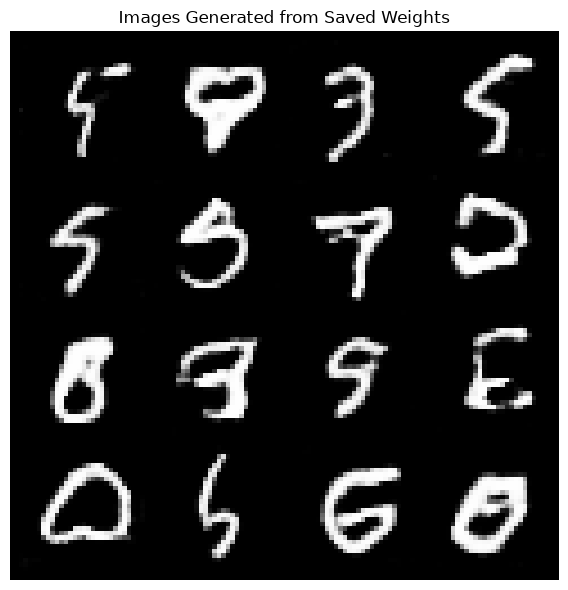

Model import successful.
Weights loaded successfully.
Output shape: (16, 1, 28, 28)


In [1]:
from pathlib import Path

import torch
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

from helper_lib.gan import Generator as APIGenerator


weights_path = (
    Path("models") / "mnist_generator_classroom_epoch_010.pth"
)

if not weights_path.is_file():
    raise FileNotFoundError(f"Model weights not found: {weights_path}")

api_generator = APIGenerator(z_dim=100)

state_dict = torch.load(
    weights_path,
    map_location="cpu",
    weights_only=True,
)

api_generator.load_state_dict(state_dict, strict=True)
api_generator.eval()

noise = torch.randn(16, 100)

with torch.no_grad():
    images = api_generator(noise)

assert images.shape == (16, 1, 28, 28)
assert torch.isfinite(images).all()

display_images = ((images + 1) / 2).clamp(0, 1)
grid = make_grid(display_images, nrow=4)

plt.figure(figsize=(6, 6))
plt.imshow(grid.permute(1, 2, 0).numpy())
plt.title("Images Generated from Saved Weights")
plt.axis("off")
plt.tight_layout()
plt.show()
plt.close()

print("Model import successful.")
print("Weights loaded successfully.")
print("Output shape:", tuple(images.shape))

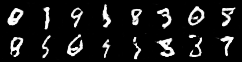

PNG generation successful.
Response size in bytes: 7691


In [2]:
from IPython.display import Image, display

from app.gan_service import generate_digits


png_bytes = generate_digits(num_samples=16)

assert png_bytes.startswith(b"\x89PNG\r\n\x1a\n")

display(Image(data=png_bytes))

print("PNG generation successful.")
print("Response size in bytes:", len(png_bytes))